In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
import warnings
warnings.filterwarnings('ignore')

In [7]:
# Load Data
data= pd.read_csv("Churn_Modelling.csv")

In [8]:
data

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [9]:
data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [10]:
data.tail()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1
9999,10000,15628319,Walker,792,France,Female,28,4,130142.79,1,1,0,38190.78,0


## Exploratory Data Analysis (EDA)

In [11]:
data.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [12]:
data.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [13]:
data.Exited.value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [14]:
data['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [15]:
data['Gender'].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [16]:
## The dataset is imbalanced — typically ~20% churned (Exited=1) vs ~80% retained.

## Data Cleaning

In [17]:
# Drop non-predictive columns
data_clean = data.drop(['RowNumber','CustomerId', 'Surname'], axis=1)

In [18]:
data_clean

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [19]:
# Fill missing values
data_clean.fillna(data_clean.median(numeric_only=True), inplace=True)

In [20]:
# Remove duplicates
data_clean.drop_duplicates(inplace=True)

In [21]:
data.drop('Geography',axis=1,inplace=True)

In [22]:
data

,RowNumber,CustomerId,Surname,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Male,42,3,75075.31,2,1,0,92888.52,1


## Feature Engineering

In [24]:
# Balance flag
data_clean['HasBalance'] = (data_clean['Balance'] > 0).astype(int)

In [26]:
data_clean.drop('Geography',axis=1,inplace=True)

In [51]:
data_clean.drop('AgeGroup',axis=1,inplace=True)

In [53]:
data_clean.drop('CreditTier',axis=1,inplace=True)

In [54]:
data_clean

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,HasBalance
0,619,0,42,2,0.00,1,1,1,101348.88,1,0
1,608,0,41,1,83807.86,1,0,1,112542.58,0,1
2,502,0,42,8,159660.80,3,1,0,113931.57,1,1
3,699,0,39,1,0.00,2,0,0,93826.63,0,0
4,850,0,43,2,125510.82,1,1,1,79084.10,0,1
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,1,39,5,0.00,2,1,0,96270.64,0,0
9996,516,1,35,10,57369.61,1,1,1,101699.77,0,1
9997,709,0,36,7,0.00,1,0,1,42085.58,1,0
9998,772,1,42,3,75075.31,2,1,0,92888.52,1,1


## Encoding Categorical Variables

In [28]:
le = LabelEncoder()
data_clean['Gender'] = le.fit_transform(data_clean['Gender'])


In [29]:
data_clean

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,AgeGroup,HasBalance,CreditTier
0,619,0,42,2,0.00,1,1,1,101348.88,1,Middle,0,Fair
1,608,0,41,1,83807.86,1,0,1,112542.58,0,Middle,1,Fair
2,502,0,42,8,159660.80,3,1,0,113931.57,1,Middle,1,Very Poor
3,699,0,39,1,0.00,2,0,0,93826.63,0,Middle,0,Good
4,850,0,43,2,125510.82,1,1,1,79084.10,0,Middle,1,Exceptional
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,1,39,5,0.00,2,1,0,96270.64,0,Middle,0,Very Good
9996,516,1,35,10,57369.61,1,1,1,101699.77,0,Middle,1,Very Poor
9997,709,0,36,7,0.00,1,0,1,42085.58,1,Middle,0,Good
9998,772,1,42,3,75075.31,2,1,0,92888.52,1,Middle,1,Very Good


In [55]:
# CORRELATION ANALYSIS
print("\n" + "=" * 60)
print("CORRELATION WITH EXITED")
print("=" * 60)
numeric_data = data.select_dtypes(include=[np.number])
print(numeric_data.corr()['Exited'].sort_values(ascending=False))


CORRELATION WITH EXITED
Exited             1.000000
Age                0.285323
Balance            0.118533
EstimatedSalary    0.012097
CustomerId        -0.006248
HasCrCard         -0.007138
Tenure            -0.014001
RowNumber         -0.016571
CreditScore       -0.027094
NumOfProducts     -0.047820
IsActiveMember    -0.156128
Name: Exited, dtype: float64


In [56]:
data.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Gender', 'Age',
       'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember',
       'EstimatedSalary', 'Exited'],
      dtype='object')

In [57]:
#  GROUPBY ANALYSIS

print("\n" + "=" * 60)
print("GROUP ANALYSIS")
print("=" * 60)
# Churn rate by Gender
print("\nChurn Rate by Gender:")
print(data_clean.groupby('Gender')['Exited'].mean() * 100)
# Avg Balance by Churn
print("\nAvg Balance by Churn Status:")
print(data_clean.groupby('Exited')['Balance'].mean())


GROUP ANALYSIS

Churn Rate by Gender:
Gender
0    25.071539
1    16.455928
Name: Exited, dtype: float64

Avg Balance by Churn Status:
Exited
0    72745.296779
1    91108.539337
Name: Balance, dtype: float64


##  Visualizations Plot

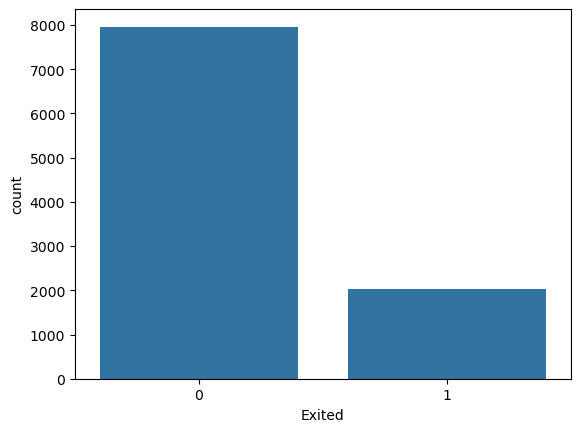

In [58]:
sns.countplot(x='Exited',data=data)
plt.show()

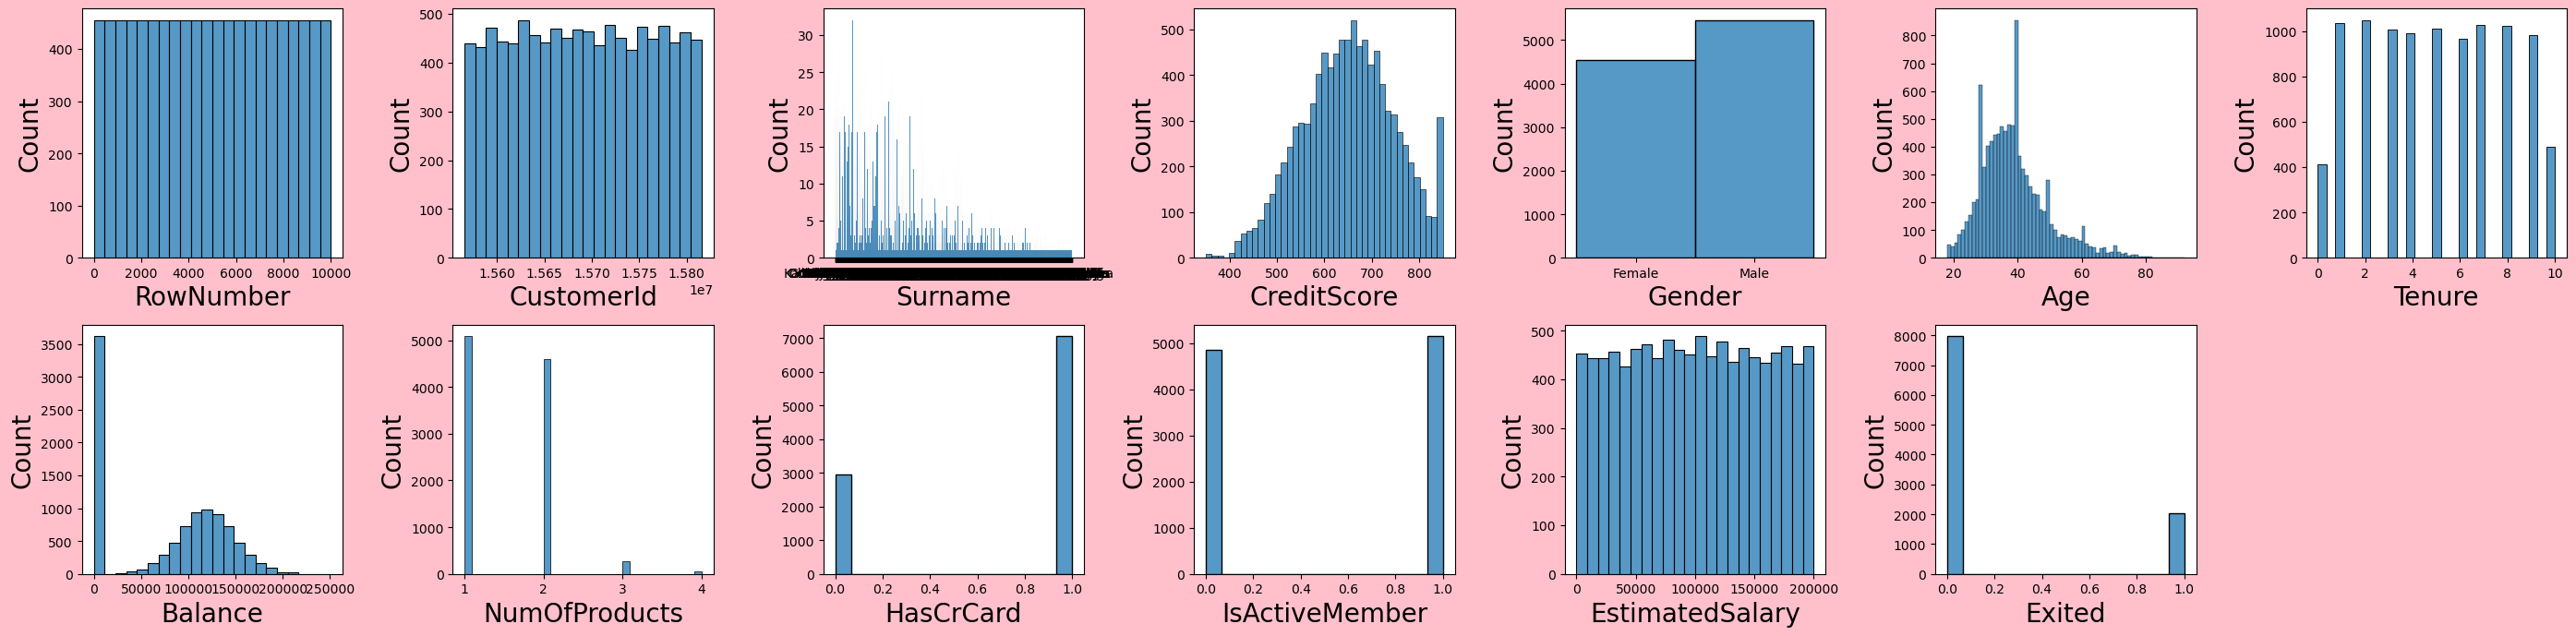

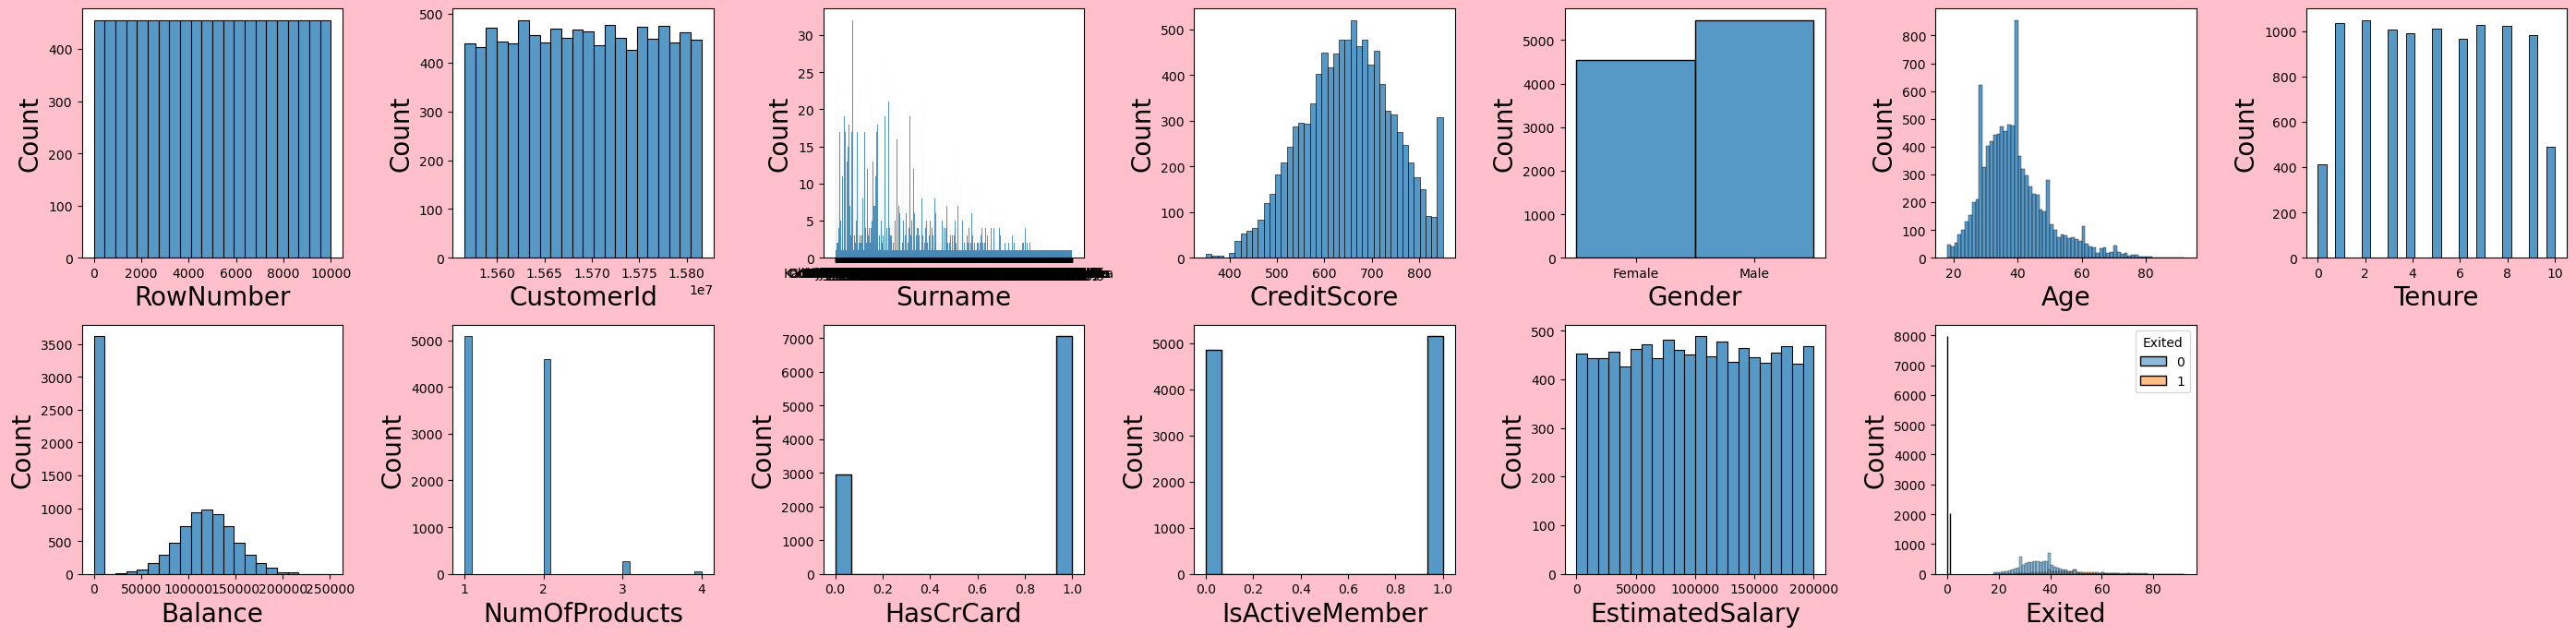

In [41]:
sns.histplot(x='Age',hue='Exited',data=data)
plt.show()

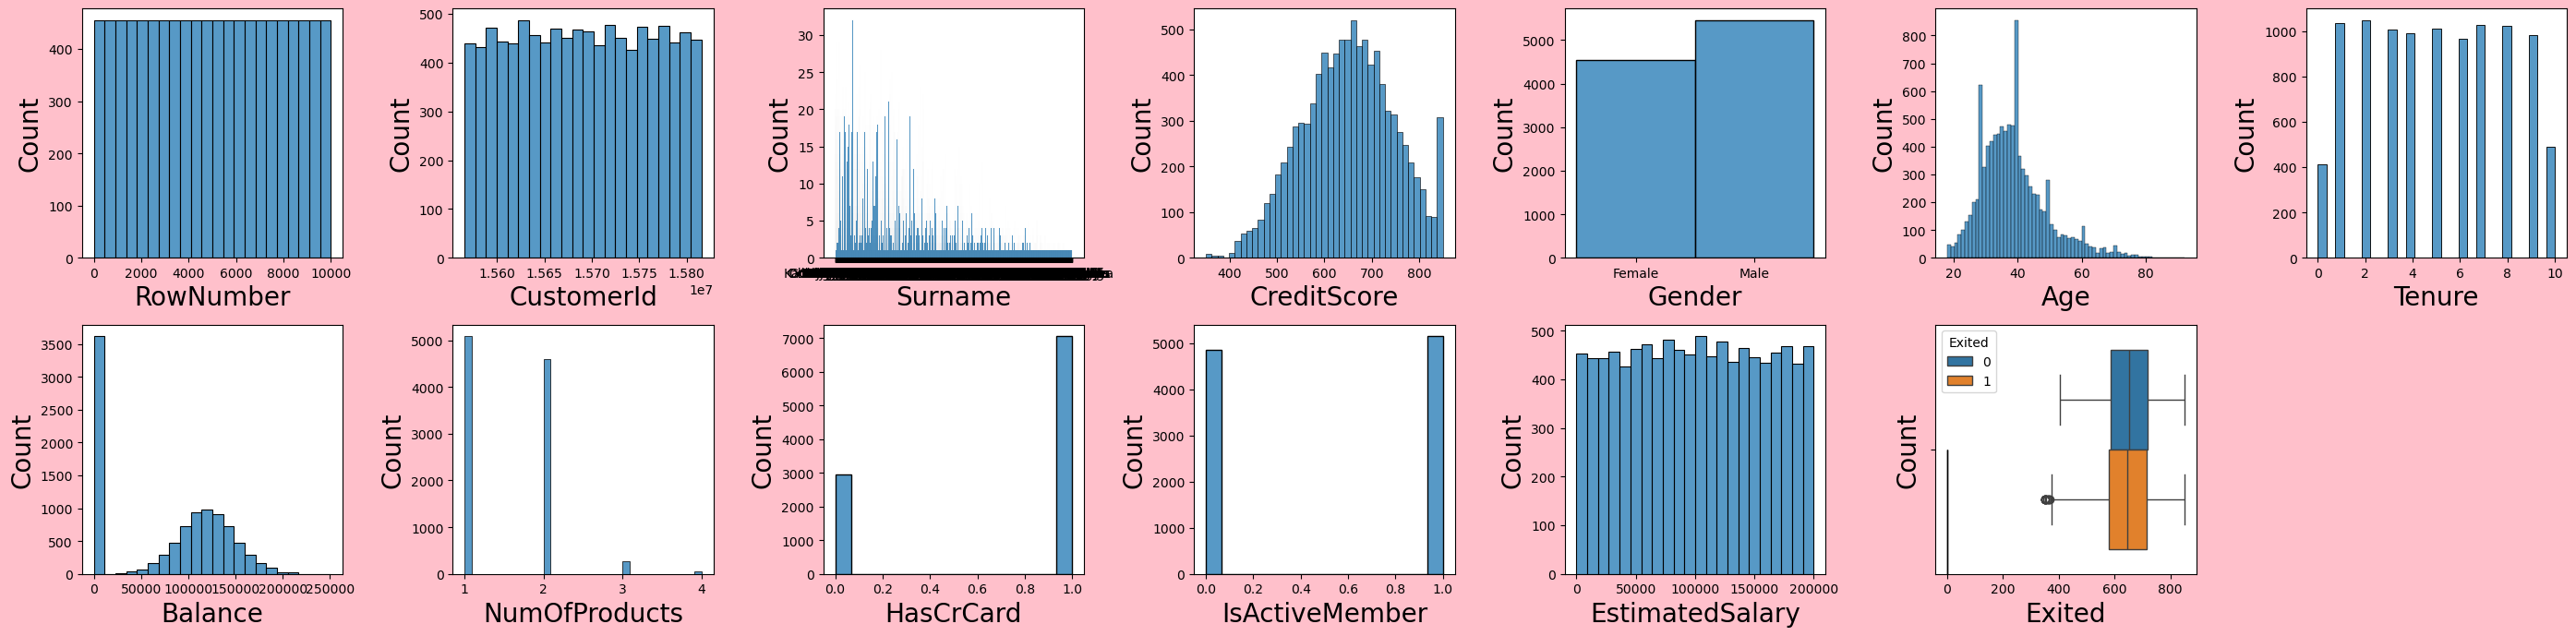

In [60]:
sns.boxplot(x='CreditScore',hue='Exited',data=data)
plt.show()

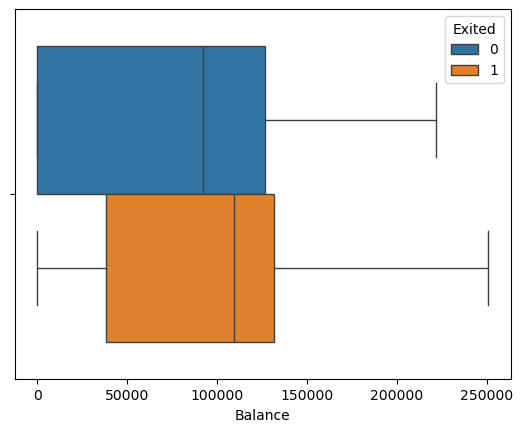

In [43]:
sns.boxplot(x='Balance',hue='Exited',data=data)
plt.show()

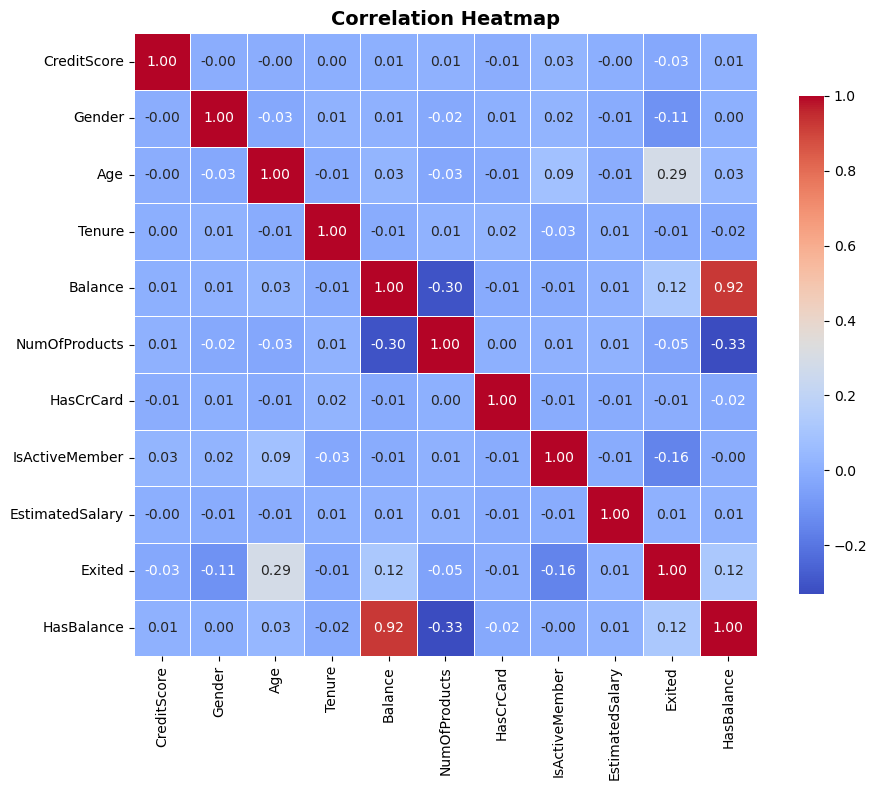

✅ Heatmap saved as churn_eda.png


In [61]:
# Select only numeric columns
numeric_df = data_clean.select_dtypes(include=['number'])

# Compute correlation
corr = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,          # show values
    fmt='.2f',           # 2 decimal places
    cmap='coolwarm',     # color scheme
    linewidths=0.5,
    square=True,
    cbar_kws={'shrink': 0.8}
)
plt.title("Correlation Heatmap", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("churn_eda.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Heatmap saved as churn_eda.png")

## Model Building

In [62]:
X = data_clean.drop('Exited', axis=1)
y = data_clean['Exited']

In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [64]:
# 4. Scale 
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)


In [66]:
print(" Scaling successful!")
print("X_train shape:", X_train_sc.shape)
print("X_test shape :", X_test_sc.shape)

 Scaling successful!
X_train shape: (8000, 10)
X_test shape : (2000, 10)


In [70]:
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_sc, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [71]:
y_pred_lr = lr.predict(X_test_sc)

In [72]:
y_pred_lr

array([0, 0, 0, ..., 1, 0, 0])

## Model Evaluation

In [74]:
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, roc_auc_score, roc_curve)

In [75]:
print(f"Accuracy : {accuracy_score(y_test, y_pred_lr):.4f}")

Accuracy : 0.8080


In [77]:
print(f"ROC-AUC  : {roc_auc_score(y_test, lr.predict_proba(X_test_sc)[:,1]):.4f}")

ROC-AUC  : 0.7698


In [80]:
print(confusion_matrix(y_test, y_pred_lr))

[[1552   41]
 [ 343   64]]


In [81]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.82      0.97      0.89      1593
           1       0.61      0.16      0.25       407

    accuracy                           0.81      2000
   macro avg       0.71      0.57      0.57      2000
weighted avg       0.78      0.81      0.76      2000

